# Воронка и удержание

Работаю с очищенной таблицей `events_clean` (правила и допущения — в [`02_cleaning.ipynb`](02_cleaning.ipynb)).

**Вопросы:** где пользователи теряются на пути «просмотр → корзина → покупка» и как возвращаются пользователи по неделям.

**Окно анализа — с 16 декабря 2019 по 31 января 2020.** События 1–15 декабря использую только как историю: по ним понимаю, был ли человек раньше.

In [1]:
import duckdb
from pathlib import Path

# корень проекта: ноутбук может запускаться и из notebooks/, и из корня
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent

# read_only: базу можно читать одновременно из ноутбука и из терминала
con = duckdb.connect(str(ROOT / 'data/processed/shop.duckdb'), read_only=True)

def q(sql):
    """Выполнить SQL и показать результат таблицей."""
    return con.sql(sql).df()

In [2]:
import matplotlib.pyplot as plt
import numpy as np

FIG = ROOT / 'reports/figures'
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#1f1f1d', '#6b6a63', '#e1e0d9'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
})

## Задача 1. Воронка по пользователям

Считаю, сколько людей дошли до каждого шага за окно анализа. Как и решила при очистке, пользователь попадает на шаг, если у него было такое событие; порядок событий не проверяю.

In [3]:
funnel = q("""
SELECT
    COUNT(DISTINCT CASE WHEN event_type = 'view'     THEN user_id END) AS viewed,
    COUNT(DISTINCT CASE WHEN event_type = 'cart'     THEN user_id END) AS carted,
    COUNT(DISTINCT CASE WHEN event_type = 'purchase' THEN user_id END) AS purchased
FROM events_clean
WHERE event_time >= '2019-12-16'
""")
funnel['view_to_cart_pct']     = (100 * funnel.carted    / funnel.viewed).round(2)
funnel['cart_to_purchase_pct'] = (100 * funnel.purchased / funnel.carted).round(2)
funnel['view_to_purchase_pct'] = (100 * funnel.purchased / funnel.viewed).round(2)
funnel

,viewed,carted,purchased,view_to_cart_pct,cart_to_purchase_pct,view_to_purchase_pct
0,552550,125626,39097,22.74,31.12,7.08


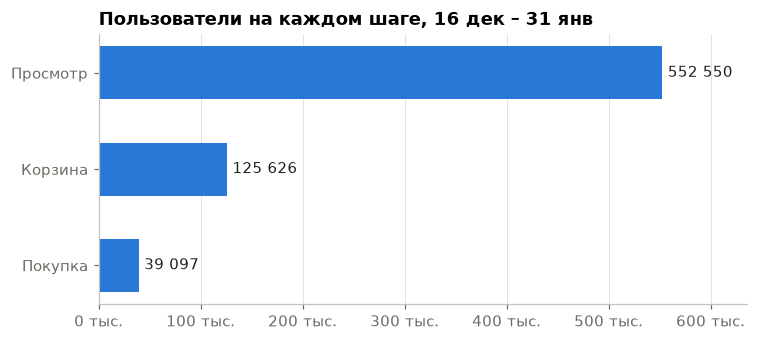

In [4]:
steps = ['Просмотр', 'Корзина', 'Покупка']
values = funnel[['viewed', 'carted', 'purchased']].iloc[0].values

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(steps[::-1], values[::-1], color=BLUE, height=0.55)
for bar, v in zip(bars, values[::-1]):
    ax.text(bar.get_width() + values[0] * 0.01, bar.get_y() + bar.get_height() / 2,
            f'{v:,.0f}'.replace(',', ' '), va='center', color=INK, fontsize=10)
ax.set_xlim(0, values[0] * 1.15)
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f} тыс.')
ax.set_title('Пользователи на каждом шаге, 16 дек – 31 янв')
plt.tight_layout()
plt.savefig(FIG / 'funnel_users.png', bbox_inches='tight')
plt.show()

### Что видно

- **Больше всего людей теряется между просмотром и корзиной.** Из 552 550 человек, которые смотрели товары, в корзину положили 125 626 — это 22,74%. То есть примерно трое из четырёх посмотрели и ушли.
- **Из корзины покупает примерно каждый третий** (31,12%). До покупки доходят 7,08% тех, кто смотрел товары.
- **Брошенные корзины — тоже большая потеря:** 69% людей с корзиной ничего не купили. Но в людях больше всего теряется на первом шаге, поэтому A/B-тест дальше придумываю для него.

Проверяю ту же воронку строго по шагам: из тех, кто смотрел, — сколько положили в корзину, а из них — сколько купили.

In [5]:
q("""
WITH users AS (
    SELECT
        user_id,
        MAX(CASE WHEN event_type = 'view'     THEN 1 ELSE 0 END) AS viewed,
        MAX(CASE WHEN event_type = 'cart'     THEN 1 ELSE 0 END) AS carted,
        MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS purchased
    FROM events_clean
    WHERE event_time >= '2019-12-16'
    GROUP BY user_id
)
SELECT
    SUM(viewed)                                   AS viewed,
    SUM(viewed * carted)                          AS viewed_and_carted,
    SUM(viewed * carted * purchased)              AS all_three_steps,
    SUM(CASE WHEN carted = 1 AND viewed = 0 THEN 1 ELSE 0 END)    AS carted_without_view,
    SUM(CASE WHEN purchased = 1 AND carted = 0 THEN 1 ELSE 0 END) AS purchased_without_cart
FROM users
""")

,viewed,viewed_and_carted,all_three_steps,carted_without_view,purchased_without_cart
0,552550.0,109757.0,36419.0,15869.0,509.0


### Что видно

- **Строгая воронка почти такая же:** 552 550 → 109 757 (19,86%) → 36 419 (33,18%). Цифры отличаются на несколько процентных пунктов, но выводы те же: главная потеря — на первом шаге.
- **15 869 человек положили товар в корзину, но не смотрели товары в окне анализа.** Скорее всего, смотрели раньше 16 декабря или добавляли товар не со страницы товара, например из каталога. Это вопрос к тому, как записываются события.
- **Покупок без корзины по людям всего 509.** По парам «пользователь и товар» их было 7–9%, но почти все такие люди корзиной пользовались для других товаров. Это совпадает с выводом из проверки качества.

## Задача 2. Устойчивость воронки

Проверяю два решения из очистки: что будет без пользователей из помеченных сессий (`is_multi_user_session`) и без всплеска 27–28 января.

In [6]:
q("""
WITH variants AS (
    SELECT 'все события' AS variant, * FROM events_clean
    WHERE event_time >= '2019-12-16'
    UNION ALL
    SELECT 'без помеченных сессий', * FROM events_clean
    WHERE event_time >= '2019-12-16'
      AND user_id NOT IN (SELECT user_id FROM events_clean WHERE is_multi_user_session)
    UNION ALL
    SELECT 'без 27–28 января', * FROM events_clean
    WHERE event_time >= '2019-12-16'
      AND event_time::date NOT IN ('2020-01-27', '2020-01-28')
)
SELECT
    variant,
    COUNT(DISTINCT CASE WHEN event_type = 'view'     THEN user_id END) AS viewed,
    COUNT(DISTINCT CASE WHEN event_type = 'cart'     THEN user_id END) AS carted,
    COUNT(DISTINCT CASE WHEN event_type = 'purchase' THEN user_id END) AS purchased,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN event_type = 'cart' THEN user_id END)
                / COUNT(DISTINCT CASE WHEN event_type = 'view' THEN user_id END), 2) AS view_to_cart_pct,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN event_type = 'purchase' THEN user_id END)
                / COUNT(DISTINCT CASE WHEN event_type = 'cart' THEN user_id END), 2) AS cart_to_purchase_pct
FROM variants
GROUP BY variant
ORDER BY viewed DESC
""")

,variant,viewed,carted,purchased,view_to_cart_pct,cart_to_purchase_pct
0,все события,552550,125626,39097,22.74,31.12
1,без помеченных сессий,552321,125572,39081,22.74,31.12
2,без 27–28 января,531850,119739,36183,22.51,30.22


Отдельно смотрю на 27–28 января: что изменилось во всплеске — больше людей или больше действий на человека.

In [7]:
q("""
SELECT
    event_time::date AS day,
    COUNT(*)                AS events,
    COUNT(DISTINCT user_id) AS users,
    ROUND(COUNT(*) / COUNT(DISTINCT user_id), 1) AS events_per_user,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN event_type = 'cart' THEN user_id END)
                / COUNT(DISTINCT user_id), 2) AS users_with_cart_pct
FROM events_clean
WHERE event_time::date BETWEEN '2020-01-20' AND '2020-01-31'
GROUP BY day
ORDER BY day
""")

,day,events,users,events_per_user,users_with_cart_pct
0,2020-01-20,144213,20310,7.1,25.41
1,2020-01-21,142187,20778,6.8,25.24
2,2020-01-22,131678,19811,6.6,24.98
3,2020-01-23,135157,20111,6.7,24.68
4,2020-01-24,128785,19012,6.8,24.12
5,2020-01-25,113766,17643,6.4,23.16
6,2020-01-26,126856,19012,6.7,24.20
7,2020-01-27,195041,22141,8.8,30.37
8,2020-01-28,174992,21143,8.3,27.68
9,2020-01-29,138222,21740,6.4,23.30


### Что видно

- **Помеченные сессии на воронку не влияют.** Без них конверсия не изменилась до сотых (22,74% и 31,12%). Теперь это проверено, а не предположено.
- **27–28 января конверсия была выше обычной.** Без этих дней конверсия в корзину 22,51% вместо 22,74%, а из корзины в покупку 30,22% вместо 31,12%.
- **Во всплеск людей стало немного больше, но главное — они больше делали.** 22 141 человек против 19–21 тысячи в обычные дни, 8,8 действия на человека против 6–7, с корзиной 30,37% людей против 23–25%. Похоже на акцию или распродажу: люди не просто зашли, а активно складывали товары в корзину. Точно мы этого не знаем.
- **Что это значит для A/B-теста.** Если тест попадёт на такие дни, метрика будет скакать. Поэтому тест держу полными неделями и проверяю, не было ли в это время акций.

## Задача 3. Воронка внутри одного визита

Та же воронка, но по сессиям: сколько визитов доходят до корзины и до покупки. Помеченные сессии и события без сессии не учитываю.

In [8]:
sessions = q("""
SELECT
    COUNT(DISTINCT user_session) AS sessions,
    COUNT(DISTINCT CASE WHEN event_type = 'cart'     THEN user_session END) AS with_cart,
    COUNT(DISTINCT CASE WHEN event_type = 'purchase' THEN user_session END) AS with_purchase
FROM events_clean
WHERE event_time >= '2019-12-16'
  AND user_session IS NOT NULL
  AND NOT is_multi_user_session
""")
sessions['cart_pct']              = (100 * sessions.with_cart     / sessions.sessions).round(2)
sessions['purchase_of_cart_pct']  = (100 * sessions.with_purchase / sessions.with_cart).round(2)
sessions

,sessions,with_cart,with_purchase,cart_pct,purchase_of_cart_pct
0,1362344,272799,46323,20.02,16.98


Если внутри визита до покупки доходит меньше, чем по людям, значит, часть людей покупает в другой визит. Проверяю, через сколько дней после первого добавления в корзину человек покупает.

In [9]:
q("""
WITH first_cart AS (
    SELECT user_id, MIN(event_time) AS cart_time
    FROM events_clean
    WHERE event_type = 'cart'
    GROUP BY user_id
),
first_purchase AS (
    SELECT user_id, MIN(event_time) AS purchase_time
    FROM events_clean
    WHERE event_type = 'purchase' AND event_time >= '2019-12-16'
    GROUP BY user_id
),
gaps AS (
    SELECT DATE_DIFF('day', c.cart_time, p.purchase_time) AS days
    FROM first_purchase p
    JOIN first_cart c ON c.user_id = p.user_id
    WHERE c.cart_time <= p.purchase_time
)
SELECT
    CASE WHEN days = 0 THEN '0: в тот же день'
         WHEN days <= 3 THEN '1–3 дня'
         WHEN days <= 7 THEN '4–7 дней'
         ELSE 'больше недели' END AS gap,
    COUNT(*) AS buyers,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM gaps
GROUP BY gap
ORDER BY MIN(days)
""")

,gap,buyers,pct
0,0: в тот же день,22408,57.9
1,1–3 дня,4757,12.3
2,4–7 дней,2163,5.6
3,больше недели,9366,24.2


### Что видно

- **Внутри одного визита до покупки доходят реже, чем по людям.** В корзину кладут в 20,02% визитов, а покупка есть только в 16,98% визитов с корзиной. По людям из корзины покупает 31,12%. Значит, многие кладут товар в корзину в один визит, а покупают в другой.
- **57,9% покупают в тот же день, когда впервые положили товар в корзину, но почти четверть (24,2%) — больше чем через неделю.** Похоже, что корзину используют как список желаний и возвращаются к ней позже.
- **Что это значит для метрик.** Конверсию из корзины в покупку нельзя считать только внутри одной сессии, иначе она будет занижена. А в A/B-тесте нужно наблюдать за людьми не меньше недели, чтобы отложенные покупки успели попасть в метрику.

## Задача 4. Когорты удержания

Когорта — неделя, когда человек впервые появился в данных. Беру когорты начиная с недели 16 декабря: тех, кто появился 1–15 декабря, могли заходить и в ноябре, поэтому «новыми» их считать нельзя. Удержание недели N — доля когорты, у которой было хоть одно событие через N недель после первой.

In [10]:
cohorts = q("""
WITH first_seen AS (
    SELECT user_id, DATE_TRUNC('week', MIN(event_time))::date AS cohort
    FROM events_clean
    GROUP BY user_id
),
activity AS (
    SELECT DISTINCT user_id, DATE_TRUNC('week', event_time)::date AS week
    FROM events_clean
)
SELECT
    f.cohort,
    DATE_DIFF('week', f.cohort, a.week) AS week_n,
    COUNT(DISTINCT a.user_id) AS users
FROM first_seen f
JOIN activity a ON a.user_id = f.user_id
WHERE f.cohort >= '2019-12-16'
GROUP BY ALL
ORDER BY f.cohort, week_n
""")
table = cohorts.pivot(index='cohort', columns='week_n', values='users')
retention = (100 * table.div(table[0], axis=0)).round(1)
retention.insert(0, 'size', table[0])
retention

week_n,size,0,1,2,3,4,5,6
cohort,,,,,,,,
2019-12-16,80237.0,100.0,8.7,4.5,4.7,4.5,4.0,3.1
2019-12-23,72864.0,100.0,6.9,5.5,4.7,4.0,2.9,NaN
2019-12-30,63296.0,100.0,9.7,6.0,4.8,3.2,NaN,NaN
2020-01-06,86068.0,100.0,9.3,6.2,4.0,NaN,NaN,NaN
2020-01-13,83869.0,100.0,9.3,5.4,NaN,NaN,NaN,NaN
2020-01-20,76461.0,100.0,8.5,NaN,NaN,NaN,NaN,NaN
2020-01-27,59110.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN


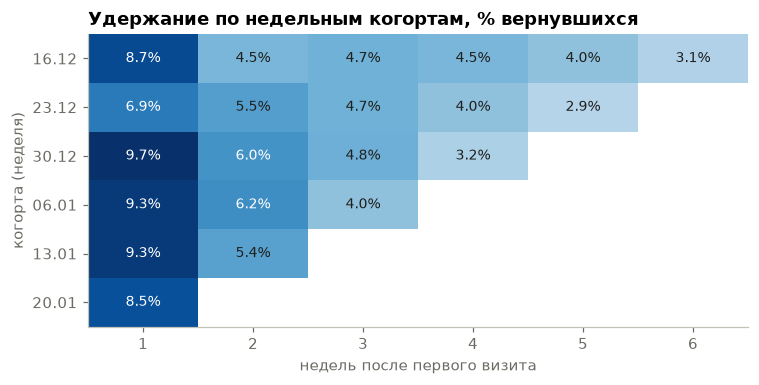

In [11]:
r = retention.drop(columns=['size', 0]).dropna(how='all')
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(r.values, cmap='Blues', vmin=0, vmax=np.nanmax(r.values), aspect='auto')
ax.grid(False)
ax.set_xticks(range(r.shape[1]), [f'{c}' for c in r.columns])
ax.set_yticks(range(r.shape[0]), [d.strftime('%d.%m') for d in r.index])
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        v = r.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.1f}%', ha='center', va='center', fontsize=9,
                    color='white' if v > np.nanmax(r.values) * 0.6 else INK)
ax.set_xlabel('недель после первого визита')
ax.set_ylabel('когорта (неделя)')
ax.set_title('Удержание по недельным когортам, % вернувшихся')
plt.tight_layout()
plt.savefig(FIG / 'cohort_retention.png', bbox_inches='tight')
plt.show()

### Что видно

- **Возвращаются мало.** Через неделю после первого визита заходят 7–10% когорты, дальше удержание держится около 4–5%. Большинство людей приходят один раз.
- **Когорта 23 декабря хуже всех на первой неделе (6,9%).** Её первая неделя после визита — новогодняя, когда в магазин заходят реже. А когорта 30 декабря, наоборот, лучше всех (9,7%): после праздников люди вернулись.
- **Последнее значение в каждой строке немного занижено.** Данные заканчиваются в пятницу 31 января, поэтому неделя 27 января неполная (5 дней из 7). Когорта 27 января совсем не успела вернуться, поэтому её в таблице нет.

Удержание всех пользователей размывают те, кто зашёл один раз. Смотрю отдельно покупателей: возвращаются ли за повторной покупкой те, кто купил впервые в окне анализа.

In [12]:
q("""
WITH buyers AS (
    SELECT user_id, MIN(event_time) AS first_purchase
    FROM events_clean
    WHERE event_type = 'purchase'
    GROUP BY user_id
    HAVING MIN(event_time) >= '2019-12-16' AND MIN(event_time) < '2020-01-01'
),
next_purchase AS (
    SELECT b.user_id,
           MIN(e.event_time) AS second_purchase
    FROM buyers b
    JOIN events_clean e
      ON e.user_id = b.user_id
     AND e.event_type = 'purchase'
     AND e.event_time > b.first_purchase + INTERVAL 1 DAY
    GROUP BY b.user_id
)
SELECT
    COUNT(*) AS first_time_buyers_16_31_dec,
    COUNT(n.user_id) AS bought_again_by_31_jan,
    ROUND(100.0 * COUNT(n.user_id) / COUNT(*), 1) AS repeat_pct
FROM buyers b
LEFT JOIN next_purchase n ON n.user_id = b.user_id
""")

,first_time_buyers_16_31_dec,bought_again_by_31_jan,repeat_pct
0,11836,1865,15.8


### Что видно

**Из 11 836 человек, которые впервые купили 16–31 декабря, до конца января купили снова 1 865 — это 15,8%.** То есть повторно покупает меньше чем каждый шестой. Оговорка: «впервые» значит «впервые в наших данных», в ноябре они могли покупать.

## Итог

1. **Главная потеря — между просмотром и корзиной:** 77% людей, которые смотрели товары, ничего не положили в корзину.
2. **Из корзины покупает 31%,** причём почти каждая четвёртая покупка случается больше чем через неделю после корзины.
3. **Выводы устойчивы.** Помеченные сессии на воронку не влияют, это проверено. 27–28 января — дни с повышенной конверсией, похоже на акцию.
4. **Удержание низкое:** через неделю возвращаются 7–10%, дальше около 4–5%; повторно покупают 15,8% новых покупателей.

**Что делаю дальше:** придумываю A/B-тест для шага «просмотр → корзина» и считаю, сколько людей и времени для него нужно, — [`04_ab_tests.ipynb`](04_ab_tests.ipynb).